# 02. Baseline pipeline и leakage-control

**Цель.** Зафиксировать честную проверочную постановку: strict pre-anchor окна, gap до сбоя, split по run/workload и baseline как нижнюю границу.


## 1. Инициализация

**Вопрос.** Какие strict/intensity артефакты используются как единый contract финального маршрута?


In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
OUT_DIR = ROOT / "outputs" / "final_notebooks"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_CONTRACT_PATH = ROOT / "outputs" / "raw_multirate" / "aligned_multirate_windows.csv"
STRICT_DIR = ROOT / "outputs" / "hades_like_v2" / "hades_v2_strict_intensity_gap10"
FINAL_ALERT_DIR = ROOT / "outputs" / "final_alert_system"

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("SEED =", SEED)
print("Выходная папка:", OUT_DIR)

DECLARED_STRICT_CONTRACT = ROOT / "outputs" / "strict_forecast" / "strict_forecast_01" / "contracts" / "strict_explicit_only_gap10.csv.gz"
print("Заявленный strict contract существует:", DECLARED_STRICT_CONTRACT.exists())


SEED = 42
Выходная папка: C:\Main\DGTU\ВКР\Diploma\outputs\final_notebooks
Заявленный strict contract существует: False


**Локальный вывод.** В финальном snapshot исходный `.csv.gz` contract может отсутствовать; воспроизводимая проверка берется из сохраненных split/prediction артефактов `hades_v2_strict_intensity_gap10`.


## 2. Contract окон и разметка

**Вопрос.** Какие цели проверяются и где появляется intensity?


In [2]:
split_summary = pd.read_csv(STRICT_DIR / "split_summary.csv")
strict_pred = pd.read_csv(STRICT_DIR / "ensemble_predictions.csv")
validation_pred = pd.read_csv(STRICT_DIR / "validation_ensemble_predictions.csv")

contract_summary = split_summary.copy()
contract_summary["contract"] = "strict_explicit_only_gap10"
contract_summary["warning_horizon_sec"] = 120
contract_summary["risk_horizon_sec"] = 30
contract_summary = contract_summary[
    ["contract", "split", "rows", "runs", "workloads", "warning_positives", "risk_positives",
     "warning_prevalence", "risk_prevalence", "log_available", "both_modalities",
     "warning_horizon_sec", "risk_horizon_sec"]
]
contract_summary


,contract,split,rows,runs,workloads,warning_positives,risk_positives,warning_prevalence,risk_prevalence,log_available,both_modalities,warning_horizon_sec,risk_horizon_sec
0,strict_explicit_only_gap10,test,795,71,4,321,94,0.403774,0.118239,0.504403,0.504403,120,30
1,strict_explicit_only_gap10,train,2050,144,9,757,203,0.369268,0.099024,0.520488,0.520488,120,30
2,strict_explicit_only_gap10,validation,750,59,3,386,90,0.514667,0.120000,0.732000,0.732000,120,30


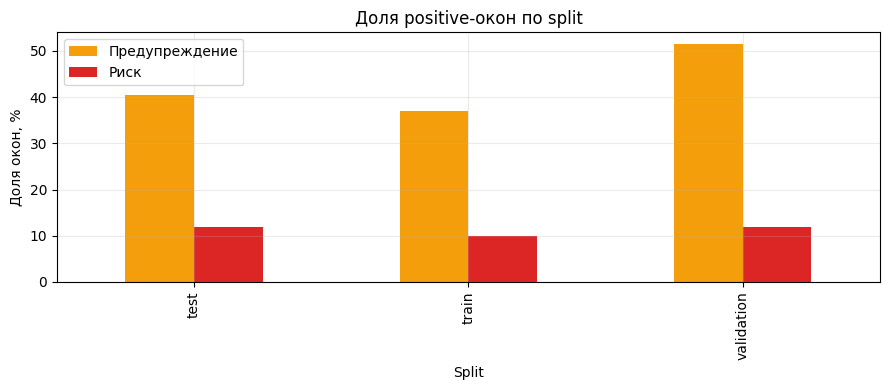

In [3]:
ax = contract_summary.set_index("split")[["warning_prevalence", "risk_prevalence"]].mul(100).plot(
    kind="bar", color=["#f59e0b", "#dc2626"]
)
ax.set_title("Доля positive-окон по split")
ax.set_ylabel("Доля окон, %")
ax.set_xlabel("Split")
ax.legend(["Предупреждение", "Риск"])
plt.tight_layout()
plt.show()


**Локальный вывод.** `risk` заметно реже `warning`; поэтому главным измерением становится AP/ranking, а не accuracy.


## 3. Split и контроль утечки

**Вопрос.** Что именно защищает постановку от самообмана?


In [4]:
leakage_control = pd.DataFrame([
    {"контроль": "split", "решение": "train/validation/test разделены по run/workload"},
    {"контроль": "gap10", "решение": "окно сбоя не используется как наблюдаемое окно для прогноза"},
    {"контроль": "test", "решение": "ключевая проверка идет на explicit failure anchors"},
    {"контроль": "dashboard", "решение": "на экране показывается score модели, а не target/proxy label"},
])
leakage_control


,контроль,решение
0,split,train/validation/test разделены по run/workload
1,gap10,окно сбоя не используется как наблюдаемое окно...
2,test,ключевая проверка идет на explicit failure anc...
3,dashboard,"на экране показывается score модели, а не targ..."


**Локальный вывод.** Утечка контролируется не архитектурой, а contract, split, gap и границей между score модели и фактом сбоя.


## 4. Baseline

**Вопрос.** Какую нижнюю границу должна превзойти финальная модель?


In [5]:
baseline = pd.read_csv(STRICT_DIR / "baseline_comparison.csv")
baseline_compact = baseline.loc[baseline["target"].isin(["y_warning", "y_risk"])].copy()
baseline_compact["роль"] = np.where(
    baseline_compact["baseline"].eq("fused"),
    "простой baseline fusion",
    "одномодальный/служебный baseline",
)
baseline_compact.sort_values(["target", "average_precision"], ascending=[True, False])


,target,baseline,average_precision,roc_auc,роль
7,y_risk,availability-only,0.141823,0.576744,одномодальный/служебный baseline
4,y_risk,log-only,0.121088,0.545528,одномодальный/служебный baseline
6,y_risk,fused,0.108005,0.474838,простой baseline fusion
5,y_risk,kpi-only,0.106154,0.480484,одномодальный/служебный baseline
1,y_warning,kpi-only,0.453644,0.548306,одномодальный/служебный baseline
2,y_warning,fused,0.436005,0.551612,простой baseline fusion
3,y_warning,availability-only,0.407808,0.500565,одномодальный/служебный baseline
0,y_warning,log-only,0.378024,0.513361,одномодальный/служебный baseline


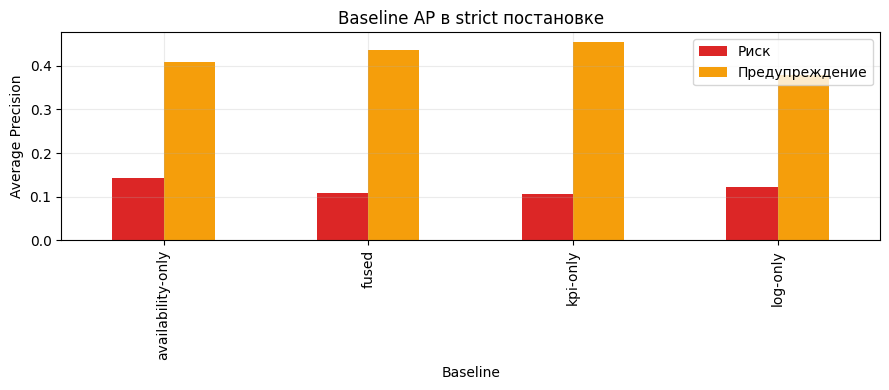

In [6]:
plot_df = baseline_compact.pivot(index="baseline", columns="target", values="average_precision").sort_index()
ax = plot_df.plot(kind="bar", color=["#dc2626", "#f59e0b"])
ax.set_title("Baseline AP в strict постановке")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Baseline")
ax.legend(["Риск", "Предупреждение"])
plt.tight_layout()
plt.show()


**Локальный вывод.** Baseline показывает нижнюю границу. Финальная модель в `03` должна оцениваться не только как binary classifier, а как strict/intensity ranking модель.


## 5. Экспорт артефактов этапа


In [7]:
contract_path = OUT_DIR / "strict_contract_summary.csv"
baseline_path = OUT_DIR / "baseline_comparison_compact.csv"
contract_summary.to_csv(contract_path, index=False)
baseline_compact.to_csv(baseline_path, index=False)

print("Записаны артефакты:")
print("-", contract_path.relative_to(ROOT))
print("-", baseline_path.relative_to(ROOT))
print("Ссылка на исходный strict contract:", DECLARED_STRICT_CONTRACT.relative_to(ROOT))


Записаны артефакты:
- outputs\final_notebooks\strict_contract_summary.csv
- outputs\final_notebooks\baseline_comparison_compact.csv
Ссылка на исходный strict contract: outputs\strict_forecast\strict_forecast_01\contracts\strict_explicit_only_gap10.csv.gz


**Итоговый вывод.** `02` фиксирует строгую проверочную рамку. В `03` не перебирается весь зоопарк гипотез: там закрепляется лучшая проверенная HADES-like strict/intensity постановка.
